# Introduction to vector databases on S&P 500 news

 # 📌 Objectives

 By the end of this notebook, students will be able to:

 1. **Load and Explore Financial News Data:**
    - Load a preprocessed dataset of financial news headlines and summaries related to S&P 500 companies.
    - Inspect and structure relevant metadata including publication date, ticker, and provider.

 2. **Build a Custom Vector Store:**
    - Combine title and summary text for embedding.
    - Implement a vector store from scratch with support for semantic search and optional metadata-based filtering using cosine similarity.

 3. **Generate and Use Sentence Embeddings:**
    - Apply a pre-trained transformer model (all-MiniLM-L6-v2) to encode text into embeddings for semantic analysis.

 4. **Perform Semantic Search with Filtering:**
    - Retrieve the most relevant news documents for a given query using both full-dataset and metadata-filtered searches.

 5. **Analyze Semantic Search Results:**
    - Interpret and visualize results of search queries (e.g., "AI announcement").
    - Identify temporal patterns and ticker frequency among top-ranked results.

 6. **Implement a FAISS-Based Vector Store:**
    - Normalize embeddings and use FAISS (IndexFlatIP) to enable efficient similarity search at scale.
    - Compare FAISS-based search results with custom vector store results.

 7. **Critically Compare Search Systems:**
    - Evaluate differences in similarity computation, speed, and scalability between custom and FAISS-based systems.
    - Reflect on design trade-offs for real-world vector search systems.

## Install and Import important librairies

In [ ]:
%pip install sentence-transformers
%pip install faiss-cpu

!pip install yfinance -q

In [ ]:
from sentence_transformers import SentenceTransformer
import faiss
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter
import matplotlib.pyplot as plt
import faiss

import textwrap
import yfinance as yf

import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
Tesla T4


## Load news data

Load the provided news dataset and inspect the contents.

 👉 **Instructions**:
 - Load the CSV file named df_news.csv into a pandas DataFrame.
 - Convert the PUBLICATION_DATE column to a proper date format (not datetime).
 - Display the first few rows to understand the data structure. The key columns you’ll be using are:
   - TITLE
   - SUMMARY
   - TICKER
   - PROVIDER
   - PUBLICATION_DATE


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_news = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Fintech _2/df_news.csv')

df_news['PUBLICATION_DATE'] = pd.to_datetime(df_news['PUBLICATION_DATE']).dt.date

display(df_news)

,TICKER,TITLE,SUMMARY,PUBLICATION_DATE,PROVIDER,URL
0,MMM,2 Dow Jones Stocks with Promising Prospects an...,The Dow Jones (^DJI) is made up of 30 of the m...,2025-05-29,StockStory,https://finance.yahoo.com/news/2-dow-jones-sto...
1,MMM,3 S&P 500 Stocks Skating on Thin Ice,The S&P 500 (^GSPC) is often seen as a benchma...,2025-05-27,StockStory,https://finance.yahoo.com/news/3-p-500-stocks-...
2,MMM,3M Rises 15.8% YTD: Should You Buy the Stock N...,"MMM is making strides in the aerospace, indust...",2025-05-22,Zacks,https://finance.yahoo.com/news/3m-rises-15-8-y...
3,MMM,Q1 Earnings Roundup: 3M (NYSE:MMM) And The Res...,Quarterly earnings results are a good time to ...,2025-05-22,StockStory,https://finance.yahoo.com/news/q1-earnings-rou...
4,MMM,3 Cash-Producing Stocks with Questionable Fund...,While strong cash flow is a key indicator of s...,2025-05-19,StockStory,https://finance.yahoo.com/news/3-cash-producin...
...,...,...,...,...,...,...
4866,ZTS,2 Dividend Stocks to Buy With $500 and Hold Fo...,Zoetis is a leading animal health company with...,2025-05-23,Motley Fool,https://www.fool.com/investing/2025/05/23/2-di...
4867,ZTS,Zoetis (NYSE:ZTS) Declares US$0.50 Dividend Pe...,Zoetis (NYSE:ZTS) recently affirmed a dividend...,2025-05-22,Simply Wall St.,https://finance.yahoo.com/news/zoetis-nyse-zts...
4868,ZTS,Jim Cramer on Zoetis (ZTS): “It Does Seem to B...,We recently published a list of Jim Cramer Tal...,2025-05-21,Insider Monkey,https://finance.yahoo.com/news/jim-cramer-zoet...
4869,ZTS,Zoetis (ZTS) Upgraded to Buy: Here's Why,Zoetis (ZTS) might move higher on growing opti...,2025-05-21,Zacks,https://finance.yahoo.com/news/zoetis-zts-upgr...


In [ ]:
#Checking df structuree
df_news.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4871 entries, 0 to 4870
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   TICKER            4871 non-null   object
 1   TITLE             4871 non-null   object
 2   SUMMARY           4871 non-null   object
 3   PUBLICATION_DATE  4871 non-null   object
 4   PROVIDER          4871 non-null   object
 5   URL               4871 non-null   object
dtypes: object(6)
memory usage: 228.5+ KB


In [ ]:
# Cheecking for NaN
df_news.isna().sum()

,0
TICKER,0
TITLE,0
SUMMARY,0
PUBLICATION_DATE,0
PROVIDER,0
URL,0


## Implement custom vector store

You will now implement a basic vector store from scratch. This class will allow you to:
1. Store embedded text and metadata.
2. Perform filtered semantic search using cosine similarity.

 👉 **Instructions**:

### Step 1: Prepare Documents
 - Combine the TITLE and SUMMARY columns into a single column named EMBEDDED_TEXT.
 - This combined text will be embedded later.

### Step 2: Load Embedding Model
 - Load the 'all-MiniLM-L6-v2' model from sentence-transformers.

### Step 3: Define CustomVectorStore Class
 Implement the class with the following methods (functions):

 - '__init__': Accepts an embedding model, list of documents, and corresponding metadata. Computes and stores embeddings for all documents.
 - search: Takes a query and returns the top k most similar documents, optionally filtered using metadata.
   - If a metadata_filter function is provided, apply it before computing similarity.
   - Use cosine similarity to compute distances.
   - Return the top k results as tuples of: (document, metadata, similarity score).

 ✅ **Requirements**:
 - Ensure the number of documents matches the number of metadata entries.
 - Make use of sklearn.metrics.pairwise.cosine_similarity.

You will test your class at the end.

In [ ]:
# Combining title and summary in a new column

df_news['EMBEDDED_TEXT'] = df_news['TITLE'] + ". " + df_news['SUMMARY']

display(df_news.head(4))

# Printing 1st value to see results
print(df_news['TITLE'].iloc[0])
print(df_news['EMBEDDED_TEXT'].iloc[0])



,TICKER,TITLE,SUMMARY,PUBLICATION_DATE,PROVIDER,URL,EMBEDDED_TEXT
0,MMM,2 Dow Jones Stocks with Promising Prospects an...,The Dow Jones (^DJI) is made up of 30 of the m...,2025-05-29,StockStory,https://finance.yahoo.com/news/2-dow-jones-sto...,2 Dow Jones Stocks with Promising Prospects an...
1,MMM,3 S&P 500 Stocks Skating on Thin Ice,The S&P 500 (^GSPC) is often seen as a benchma...,2025-05-27,StockStory,https://finance.yahoo.com/news/3-p-500-stocks-...,3 S&P 500 Stocks Skating on Thin Ice. The S&P ...
2,MMM,3M Rises 15.8% YTD: Should You Buy the Stock N...,"MMM is making strides in the aerospace, indust...",2025-05-22,Zacks,https://finance.yahoo.com/news/3m-rises-15-8-y...,3M Rises 15.8% YTD: Should You Buy the Stock N...
3,MMM,Q1 Earnings Roundup: 3M (NYSE:MMM) And The Res...,Quarterly earnings results are a good time to ...,2025-05-22,StockStory,https://finance.yahoo.com/news/q1-earnings-rou...,Q1 Earnings Roundup: 3M (NYSE:MMM) And The Res...


2 Dow Jones Stocks with Promising Prospects and 1 to Avoid
2 Dow Jones Stocks with Promising Prospects and 1 to Avoid. The Dow Jones (^DJI) is made up of 30 of the most established and influential companies in the market. But even blue-chip stocks can struggle - some are dealing with slowing growth, outdated business models, or increasing competition.


In [ ]:
# Loading the Embedded Model
model = SentenceTransformer('all-MiniLM-L6-v2', device='cuda')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [ ]:
# Custom Vector Class

class CustomVectorStore:
    def __init__(self, model, documents, metadata):
        # Guard: documents and metadata must stay aligned by position
        assert len(documents) == len(metadata), "Documents and metadata must match in length"
        self.model = model
        self.documents = documents
        self.metadata = metadata
        # Precompute embeddings for all documents upfront (so search only needs to embed the query)
        self.embeddings = self.model.encode(documents, show_progress_bar=True)

    def search(self, query, k=5, metadata_filter=None):
        # Filter first (before computing similarity) to avoid wasted computation
        if metadata_filter is not None:
            indices = [i for i, meta in enumerate(self.metadata) if metadata_filter(meta)]
        else:
            indices = list(range(len(self.documents)))  # no filter = keep all original positions

        filtered_embeddings = self.embeddings[indices]
        query_embedding = self.model.encode([query])

        # Cosine similarity between query and each (filtered) document embedding
        similarities = cosine_similarity(query_embedding, filtered_embeddings)[0]

        # Sort descending (argsort is ascending by default, so reverse) and keep top k
        top_k_idx = np.argsort(similarities)[::-1][:k]

        results = []
        for idx in top_k_idx:
            # Map filtered-array position back to the original document/metadata position
            original_idx = indices[idx]
            document = self.documents[original_idx]
            metadata = self.metadata[original_idx]
            similarity = similarities[idx]  # similarities is indexed by filtered position, not original

            results.append((document, metadata, similarity))

        return results


## Create and populate the vector store

 👉 **Instructions**:
 - Convert the combined EMBEDDED_TEXT column into a list of strings.
 - Create a metadata list of dictionaries for each document with keys:
   - 'PUBLICATION_DATE'
   - 'TICKER'
   - 'PROVIDER'
 - Instantiate your CustomVectorStore using:
   - The embedding model.
   - The list of document strings.
   - The metadata list.

 After initializing the store, you should be able to perform searches using:
'store.search("Apple earnings", k=3)'


In [ ]:
# Converting EMBEDDED_TEXT into a list of strings

documents = df_news['EMBEDDED_TEXT'].tolist()
type(documents)

list

In [ ]:
# Seeing first 2 elements of document list

documents[0:2]

['2 Dow Jones Stocks with Promising Prospects and 1 to Avoid. The Dow Jones (^DJI) is made up of 30 of the most established and influential companies in the market. But even blue-chip stocks can struggle - some are dealing with slowing growth, outdated business models, or increasing competition.',
 '3 S&P 500 Stocks Skating on Thin Ice. The S&P 500 (^GSPC) is often seen as a benchmark for strong businesses, but that doesn’t mean every stock is worth owning. Some companies face significant challenges, whether it’s stagnating growth, heavy debt, or disruptive new competitors.']

In [ ]:
# Building the Metadata list

metadata = df_news[['PUBLICATION_DATE', 'TICKER', 'PROVIDER']].to_dict(orient='records')
# orient='records' → list of {col: value} dicts per row, matching CustomVectorStore's expected format


In [ ]:
# Seeing first 2 elements of metadata list of dictionaries
metadata[0:2]

[{'PUBLICATION_DATE': datetime.date(2025, 5, 29),
  'TICKER': 'MMM',
  'PROVIDER': 'StockStory'},
 {'PUBLICATION_DATE': datetime.date(2025, 5, 27),
  'TICKER': 'MMM',
  'PROVIDER': 'StockStory'}]

In [ ]:
# Initiating the vector store

store = CustomVectorStore(model, documents, metadata)

Batches:   0%|          | 0/153 [00:00<?, ?it/s]

In [ ]:
# Dimentions sanity check

print(len(documents), len(metadata))          # should match 4871 4871
print(store.embeddings.shape)                   # should be (4871, 384)

4871 4871
(4871, 384)


In [ ]:
# Test with example query

results = store.search("NVDIA", k=3)
for doc, meta, score in results:
    print(f"{score:.3f} | {meta['TICKER']} | {meta['PUBLICATION_DATE']} | {doc[:130]}")

0.463 | NVDA | 2025-05-31 | NVIDIA First Quarter 2026 Earnings: Revenues Beat Expectations, EPS Lags. NVIDIA ( NASDAQ:NVDA ) First Quarter 2026 Results Key Fi
0.462 | HPQ | 2025-05-29 | Stocks to Watch Recap: Nvidia, E.l.f., Salesforce, HP. ↗️ Nvidia (NVDA): The chip maker's results showed sales continued to boom, 
0.382 | ACN | 2025-05-23 | Accenture, Nvidia, and Dell Technologies Partner to Capitalize on Growing AI Demand. Accenture plc (NYSE:ACN), a leading provider 


## Using your vector store and analyzing the results

### Retrieve AI Announcements

 Now that your vector store is working, let's use it to retrieve relevant documents.

 👉 **Instructions**:
 - Perform a semantic search using the query `"AI announcement"` with `k=50` to retrieve the top 50 most relevant articles.
 - Display each result's:
   - `TICKER`
   - `PUBLICATION_DATE`
   - `PROVIDER`
   - Similarity score
   - Full document text


In [ ]:
ai_results = store.search("AI announcement", k=50)

print('>'*100)
print("Custom Vector Store Results: AI announcement")
print('<'*100)
print()

for i, (doc, meta, score) in enumerate(ai_results, 1):
    print("-"*100)
    print(f"{i}. {meta['TICKER']} | {meta['PUBLICATION_DATE']} | {meta['PROVIDER']} | Score: {score:.3f}")
    print()
    #print(textwrap.fill(doc, width=100))
    print(textwrap.fill(doc, width=100, initial_indent="   ", subsequent_indent="   "))
    print()

>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
Custom Vector Store Results: AI announcement
<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<

----------------------------------------------------------------------------------------------------
1. JKHY | 2025-03-17 | Insider Monkey | Score: 0.557

   Jack Henry (JKHY) Integrates AI-Driven Lending Tech With Algebrik. We recently published a list
   of 12 AI News Investors Should Not Miss This Week. In this article, we are going to take a look
   at where Jack Henry & Associates, Inc. (NASDAQ:JKHY) stands against other AI news Investors
   should not miss this week. Artificial Intelligence (AI) is known to increase productivity,
   decrease human error, […]

----------------------------------------------------------------------------------------------------
2. ADBE | 2025-05-27 | Investor's Business Daily | Score: 0.552

   AI Stocks F

 ### **Q1.** What are the top companies (by TICKER) most frequently appearing in the top 50 search results for the query "AI announcement"?  
 Check their company names on Yahoo Finance. Are you surprised by the results?

 ✅ **Your task**:
 - Count the number of times each TICKER appears.
 - Print and analyze the top results.

In [ ]:
# Extract just the TICKER from each (document, metadata, score) result tuple
tickers = [meta['TICKER'] for doc, meta, score in ai_results]

# Count how many times each ticker appears in the top-50 results
ticker_counts = Counter(tickers)


In [ ]:
# printing most common first
for ticker, count in ticker_counts.most_common(11):
    print(f"{ticker}: {count}")

PLTR: 5
BKR: 3
AMD: 3
QCOM: 2
GOOG: 2
AMZN: 2
EXPE: 2
MSFT: 2
CTSH: 2
INTC: 2
JKHY: 1


In [ ]:
# Getting ticker/company names with yfinance

# lisft of the top 10
top_tickers = [t for t, c in ticker_counts.most_common(10)]

# Printing namees using yf
for ticker in top_tickers:
    info = yf.Ticker(ticker).info
    name = info.get('longName', 'N/A')
    print(f"{ticker}: {name} -----> (count: {ticker_counts[ticker]})")

PLTR: Palantir Technologies Inc. -----> (count: 5)
BKR: Baker Hughes Company -----> (count: 3)
AMD: Advanced Micro Devices, Inc. -----> (count: 3)
QCOM: QUALCOMM Incorporated -----> (count: 2)
GOOG: Alphabet Inc. -----> (count: 2)
AMZN: Amazon.com, Inc. -----> (count: 2)
EXPE: Expedia Group, Inc. -----> (count: 2)
MSFT: Microsoft Corporation -----> (count: 2)
CTSH: Cognizant Technology Solutions Corporation -----> (count: 2)
INTC: Intel Corporation -----> (count: 2)


#### Observations:
> Most of these results are not surprising: **Palantir, AMD, Qualcomm, Alphabet, Microsoft, and Intel** are all companies with heavily publicized AI product lines, partnerships, or chip announcements, so it makes sense they dominate semantic search results for "AI announcement." Palantir's top rank (5 mentions) is consistent with its well-known AI-platform marketing strategy (AIP) throughout 2024–2025.

> What is somewhat surprising is the presence of **Baker Hughes** (an oilfield services company) and **Expedia** (a travel booking company) in the top results, since neither is core to the "AI" narrative. This likely reflects the retrieval model surfacing generic mentions of AI adoption in operational or product contexts

### **Q2.** What is the date range of the top 50 results? Are the articles evenly distributed across time?

 ✅ **Your task**:
 - Extract the publication dates of the top 50 results.
 - Plot a histogram to visualize the temporal distribution.
 - Reflect: Are these mentions clustered in recent months or spread evenly?

 🧠 **Follow-up**: What could explain the timing of increased AI announcements?

In [ ]:
# Extract just the PUBLICATION_DATE from each (document, metadata, score) result tuple
pub_dates = [meta['PUBLICATION_DATE'] for doc, meta, score in ai_results]


print(f"Earliest: {min(pub_dates)}")
print(f"Latest: {max(pub_dates)}")
print(f"Range: {(max(pub_dates) - min(pub_dates)).days} days")

Earliest: 2025-03-17
Latest: 2025-05-31
Range: 75 days


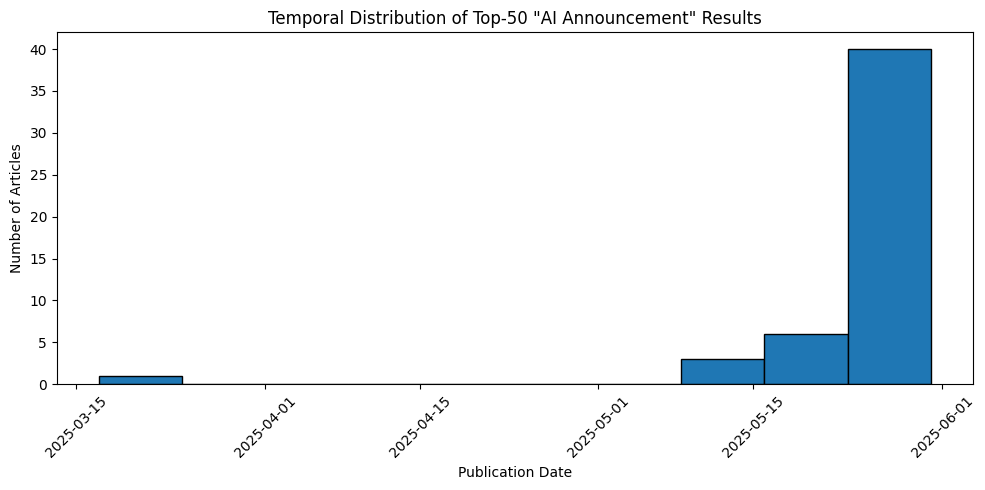

In [ ]:
# Histogram plot

plt.figure(figsize=(10, 5))
plt.hist(pub_dates, bins=10, edgecolor='black')
plt.xlabel('Publication Date')
plt.ylabel('Number of Articles')
plt.title('Temporal Distribution of Top-50 "AI Announcement" Results')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Checking all dataset publications dates
df_news['PUBLICATION_DATE'].value_counts()

,count
PUBLICATION_DATE,
2025-05-30,628
2025-05-29,520
2025-05-28,365
2025-05-27,254
2025-05-23,245
...,...
2024-12-16,1
2024-11-12,1
2024-11-10,1


<Axes: >

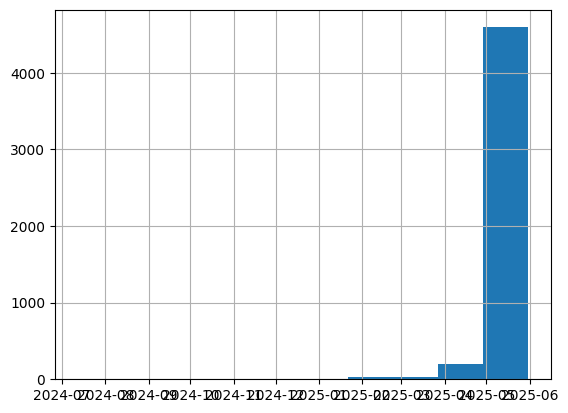

In [ ]:
df_news['PUBLICATION_DATE'].hist(bins=10)

#### Observations

> The top-50 "AI announcement" results span mostly mid-March 2025 to early June 2025, with 80% of articles (40/50) concentrated in the final days of that range (~May 28–30, 2025).

> However, checking the full dataset's date distribution (`df_news['PUBLICATION_DATE'].value_counts()`) reveals the same skew: 2025-05-30 alone has 628 articles, 2025-05-29 has 520, and 2025-05-28 has 365, while most earlier dates (back to late 2024) have only 1–5 articles each, across 121 unique dates total.

> This confirms the clustering seen in the AI-announcement results is **not a genuine temporal pattern in AI news specifically** — it's an artifact of the dataset's collection method, which appears to have gathered disproportionately more articles for the days closest to the data pull date than for earlier periods. In other words, the "increase" in AI announcements near the end of May reflects overall data volume increasing at that time, not necessarily a real surge in AI-related corporate activity. A more reliable analysis of genuine AI-news timing would require normalizing by the total article count per day (e.g., computing the proportion of AI-related articles among all articles published that day) rather than raw counts.

> It's possible that late-May earnings season (common for companies with April fiscal quarter-ends) also contributes some additional AI-related coverage volume, but since the full dataset shows the same clustering pattern independent of topic, the dominant explanation is a data collection artifact rather than a genuine earnings-driven news cycle.

## Implement FAISS vector store

 We’ll now implement a **FAISS-based vector store**, designed for efficient similarity search at scale.

 👉 **Steps**:
 - Use the same sentence transformer model: all-MiniLM-L6-v2.
 - Encode your text into embessings
 - Normalize the vectors.

 FAISS supports multiple similarity types. For cosine similarity, we must:

 ✅ Normalize vectors to unit length  
 ✅ Use `IndexFlatIP` (inner product), because:
 - For normalized vectors, inner product = cosine similarity


In [ ]:
# Encode and Normalize

# Encode all documents with the same model used in the custom store
embeddings = model.encode(documents, show_progress_bar=True)

# Normalize each embedding vector to unit length (L2 norm = 1)
faiss.normalize_L2(embeddings)

Batches:   0%|          | 0/153 [00:00<?, ?it/s]

We’ll now:
 - Initialize the FAISS index
 - Add the document embeddings

In [ ]:
# Initialize the FAISS Index and Add Embeddings

dimension = embeddings.shape[1]  # 384 for all-MiniLM-L6-v2
index = faiss.IndexFlatIP(dimension)

index.add(embeddings)

### Create a `FaissVectorStore` class with a `.search()` method.

 This method:
 - Encodes and normalizes the query
 - Optionally applies metadata filters
 - Returns top `k` results with similarity scores and metadata

In [ ]:
class FaissVectorStore:

    def __init__(self, model, documents, metadata, index):
        assert len(documents) == len(metadata), "Documents and metadata must match in length"
        self.model = model
        self.documents = documents
        self.metadata = metadata
        self.index = index

    def search(self, query, k=5, metadata_filter=None):

        # Encode and normalize the query the same way documents were normalized
        query_embedding = self.model.encode([query]).astype('float32')
        faiss.normalize_L2(query_embedding)

        # Over-fetch if filtering, since some candidates may get discarded
        search_k = k * 10 if metadata_filter is not None else k
        search_k = min(search_k, self.index.ntotal)

        scores, indices = self.index.search(query_embedding, search_k)

        results = []
        for score, idx in zip(scores[0], indices[0]):
            if idx == -1:
                continue  # FAISS pads with -1 if fewer than search_k matches exist
            meta = self.metadata[idx]
            if metadata_filter is not None and not metadata_filter(meta): #applying filter
                continue
            results.append((self.documents[idx], meta, score))
            if len(results) == k:
                break

        return results

In [ ]:
# Instantiate the FAISS-based vector store
faiss_store = FaissVectorStore(model, documents, metadata, index)

In [ ]:
# Test - search for top-3 most similar documents to the query "NVIDIA"
faiss_results = faiss_store.search("NVIDIA", k=3)

# Print ticker, date, and a preview of each matched document, sorted by similarity
for doc, meta, score in faiss_results:
    print(f"{score:.3f} | {meta['TICKER']} | {meta['PUBLICATION_DATE']} | {doc[:100]}")

0.526 | HPQ | 2025-05-29 | Stocks to Watch Recap: Nvidia, E.l.f., Salesforce, HP. ↗️ Nvidia (NVDA): The chip maker's results sh
0.507 | NVDA | 2025-05-31 | NVIDIA First Quarter 2026 Earnings: Revenues Beat Expectations, EPS Lags. NVIDIA ( NASDAQ:NVDA ) Fir
0.502 | CSCO | 2025-05-30 | How this Nvidia rival is trying to take chunks of its market share. Groq founder and CEO Jonathan Ro


 Let’s run a semantic search using FAISS:
 - Query: `"AI announcement"`
 - Top results: `k=50`

 Print out:
 - Ticker
 - Publication date
 - Provider
 - Cosine similarity score
 - Full text

In [ ]:
faiss_ai_results = faiss_store.search("AI announcement", k=50)

print('>'*100)
print("FAISS-based Vector Store Results: AI announcement")
print('<'*100)
print()

for i, (doc, meta, score) in enumerate(faiss_ai_results, 1):
    print("-"*100)
    print(f"{i}. {meta['TICKER']} | {meta['PUBLICATION_DATE']} | {meta['PROVIDER']} | Score: {score:.3f}")
    print()
    print(textwrap.fill(doc, width=100, initial_indent="   ", subsequent_indent="   "))
    print()

>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
FAISS-based Vector Store Results: AI announcement
<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<

----------------------------------------------------------------------------------------------------
1. JKHY | 2025-03-17 | Insider Monkey | Score: 0.557

   Jack Henry (JKHY) Integrates AI-Driven Lending Tech With Algebrik. We recently published a list
   of 12 AI News Investors Should Not Miss This Week. In this article, we are going to take a look
   at where Jack Henry & Associates, Inc. (NASDAQ:JKHY) stands against other AI news Investors
   should not miss this week. Artificial Intelligence (AI) is known to increase productivity,
   decrease human error, […]

----------------------------------------------------------------------------------------------------
2. ADBE | 2025-05-27 | Investor's Business Daily | Score: 0.552

   AI Sto

## Evaluation: Comparing FAISS Vector Store with your Custom Vector Store

### Retrieval Comparison Across Systems

 👉 **Instructions**:

 - Using the 5 'test_queries' provided in the list below, retrieve the top 5 news for each query using both your custom and FAISS vector stores.
 - Inspect how similar the returned news texts are for each query.
 - Focus especially on the order of results (not just their presence).


In [ ]:
test_queries = [
    'Stock price drop',
    'Layoffs',
    'Mergers and acquisitions',
    'Fed interest rate',
    'Regulation',
    'Cryptocurrency'

]

In [ ]:
# Compare CustomVectorStore vs FaissVectorStore across all test queries
for query in test_queries:
    print("="*100)
    print(f"QUERY: {query}")
    print("="*100)

    # Get top-5 results from each system for the same query
    custom_results = store.search(query, k=5)
    faiss_results = faiss_store.search(query, k=5)

    # Pull just the tickers from each result set, for quick rank-by-rank comparison
    custom_tickers = [meta['TICKER'] for doc, meta, score in custom_results]
    faiss_tickers = [meta['TICKER'] for doc, meta, score in faiss_results]

    print("\n--- CustomVectorStore ---")
    for i, (doc, meta, score) in enumerate(custom_results, 1):
        match = "✓" if meta['TICKER'] == faiss_tickers[i-1] else "✗"
        print(f"{i}. {meta['TICKER']} | Score: {score:.3f} | {doc[:80]} | {match}")

    print("\n--- FaissVectorStore ---")
    for j, (doc2, meta2, score2) in enumerate(faiss_results, 1):
        match = "✓" if meta2['TICKER'] == custom_tickers[j-1] else "✗"
        print(f"{j}. {meta2['TICKER']} | Score: {score2:.3f} | {doc2[:80]} | {match}")

    # Use Counter (multiset) instead of set, so duplicate articles aren't collapsed
    custom_docs = Counter(doc for doc, meta, score in custom_results)
    faiss_docs = Counter(doc for doc, meta, score in faiss_results)
    overlap_counter = custom_docs & faiss_docs
    overlap_count = sum(overlap_counter.values())

    print(f"\nDocument overlap: {overlap_count}/5 identical articles appear in both top-5 lists")
    print()

QUERY: Stock price drop

--- CustomVectorStore ---
1. GNRC | Score: 0.543 | 3 Industrials Stocks Walking a Fine Line. Even if they go mostly unnoticed, indu | ✓
2. NOW | Score: 0.541 | ServiceNow (NOW) Stock Drops Despite Market Gains: Important Facts to Note. Serv | ✓
3. CRL | Score: 0.540 | Guardant Health, Evolent Health, Charles River Laboratories, Avantor, and Lumen  | ✓
4. KR | Score: 0.539 | Kroger (KR) Stock Drops Despite Market Gains: Important Facts to Note. Kroger (K | ✓
5. PTC | Score: 0.537 | 2 Stocks Down 46% and 14% to Buy Right Now. AMD probably won't beat Nvidia in th | ✓

--- FaissVectorStore ---
1. GNRC | Score: 0.543 | 3 Industrials Stocks Walking a Fine Line. Even if they go mostly unnoticed, indu | ✓
2. NOW | Score: 0.541 | ServiceNow (NOW) Stock Drops Despite Market Gains: Important Facts to Note. Serv | ✓
3. CRL | Score: 0.540 | Guardant Health, Evolent Health, Charles River Laboratories, Avantor, and Lumen  | ✓
4. KR | Score: 0.539 | Kroger (KR) Stock Drops Des

### **Q3.** Do you observe any significant differences in the top-5 retrieved results for each query between the two systems? Explain why these differences may or may not occur.

> Across all 6 test queries, CustomVectorStore and FaissVectorStore returned identical top-5 document sets (5/5 overlap) every time. The only differences were in ranking order, and every reordering occurred at an exact score tie, never between documents with distinct scores.

> Investigating these ties showed a consistent cause: each tied pair was actually **the same news article appearing twice under two different tickers**, for example, the Synopsys/Ansys merger story tagged as both SNPS and ANSS, or a freight-layoffs story tagged as both UPS and FDX. Since the text is identical, both systems compute identical embeddings and therefore identical similarity scores, a genuine tie, not an approximation. "Stock price drop" had no such duplicates and showed perfect rank agreement, supporting this explanation.

> When scores tie exactly, ordering depends on implementation details unrelated to similarity itself, such as `np.argsort`'s tie-breaking vs. FAISS's internal ranking, not a disagreement about relevance. Both systems correctly retrieve both duplicate rows, they just order the tie differently. Overall, the two implementations are functionally equivalent for this dataset: the only divergence is a harmless tie-break artifact on duplicate-content rows.


## Evaluation: Comparing 2 embedding models with your Custom Vector Store

 👉 **Instructions**:

 - Implement your custom vector store with `'all-MiniLM-L6-v2'` model from `sentence-transformers`, and compare it with the `'all-mpnet-base-v2'` model from `sentence-transformers`.
 - Similarly, retrieve the top 5 news for each query using both implementations.
 - Inspect how similar the returned news texts are for each query.
 - Focus especially on the order of results (not just their presence).

In [ ]:
# Loading sceond model
model_mpnet = SentenceTransformer('all-mpnet-base-v2')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [ ]:
# Building MPNET correspoding Vector Store with custom class

store_mpnet = CustomVectorStore(model_mpnet, documents, metadata)

Batches:   0%|          | 0/153 [00:00<?, ?it/s]

In [ ]:
# Compare retrieval quality between two embedding models, both using CustomVectorStore
for query in test_queries:
    print("="*160)
    print(f"QUERY: {query}")
    print("="*160)

    # Get top-5 results for the same query from each model's vector store
    minilm_results = store.search(query, k=5)
    mpnet_results = store_mpnet.search(query, k=5)

    print("\n--- all-MiniLM-L6-v2 ---")
    for i, (doc, meta, score) in enumerate(minilm_results, 1):
        print(f"{i}. {meta['TICKER']} | Score: {score:.3f} | {doc[:130]}")

    print("\n--- all-mpnet-base-v2 ---")
    for j, (doc2, meta2, score2) in enumerate(mpnet_results, 1):
        print(f"{j}. {meta2['TICKER']} | Score: {score2:.3f} | {doc2[:130]}")

    print()

QUERY: Stock price drop

--- all-MiniLM-L6-v2 ---
1. GNRC | Score: 0.543 | 3 Industrials Stocks Walking a Fine Line. Even if they go mostly unnoticed, industrial businesses are the backbone of our country.
2. NOW | Score: 0.541 | ServiceNow (NOW) Stock Drops Despite Market Gains: Important Facts to Note. ServiceNow (NOW) reachead $1,015.23 at the closing of 
3. CRL | Score: 0.540 | Guardant Health, Evolent Health, Charles River Laboratories, Avantor, and Lumen Stocks Trade Down, What You Need To Know. A number
4. KR | Score: 0.539 | Kroger (KR) Stock Drops Despite Market Gains: Important Facts to Note. Kroger (KR) closed at $67.83 in the latest trading session,
5. PTC | Score: 0.537 | 2 Stocks Down 46% and 14% to Buy Right Now. AMD probably won't beat Nvidia in the AI processor market, but investors should look a

--- all-mpnet-base-v2 ---
1. ALGN | Score: 0.640 | Fortune Brands, Whirlpool, Align Technology, Tandem Diabetes, and STAAR Surgical Shares Plummet, What You Need To Know. A n

### **Q4.**  Which embedding model performs better in retrieving relevant documents for the queries? Support your answer with specific examples from the results.

Neither model dominates across all queries; each has query-dependent strengths, but the comparison reveals a clear trade-off between semantic breadth and keyword precision:

> **all-mpnet-base-v2 performed better** on queries where the relevant articles use varied phrasing rather than the literal query terms. For "Stock price drop," mpnet's top-5 (ALGN, DHR, HPQ, CRL, CBRE) all use direct drop-language ("Plummet," "Tumbles," "Falling") with much higher similarity scores (0.59–0.64) than MiniLM's (0.54–0.57), while MiniLM included a weaker match (GNRC, a general industrials piece not specifically about a price drop). For "Cryptocurrency," mpnet surfaced more diverse relevant companies (CME expanding crypto offerings, Fifth Third studying crypto assets) instead of MiniLM's three near-duplicate Coinbase (COIN) articles, giving a richer, less redundant result set.

> **all-MiniLM-L6-v2 performed better** on queries with strong literal keyword overlap, where mpnet's broader semantic reach introduced tangential results. For "Mergers and acquisitions," mpnet ranked an apparently unrelated article (PSX, "50 Huge Companies You've Never Heard of Before") at position 2, while MiniLM's full top-5 stayed consistently on-topic. For "Layoffs," mpnet's ranks 4–5 (DG, CRWD, "Investing Action Plan... May Payrolls") were a general market recap only loosely tied to employment, whereas MiniLM's results were tightly focused on literal layoff announcements (FedEx, three Chevron articles, UPS). Similarly, for "Fed interest rate," MiniLM's top-2 directly matched "Fed Leaves Interest Rates Unchanged," while mpnet's top result concerned carried-interest taxation, a related but looser match to the query's intent.

> **Overall**, all-mpnet-base-v2 (768 dimensions, a larger and more capable transformer) appears to capture deeper semantic relationships and produces more topically diverse, higher-confidence matches when the relevant content doesn't share exact vocabulary with the query. However, this same semantic flexibility occasionally pulls in tangentially related content that a stricter, more literal model like MiniLM avoids. For this dataset's queries, MiniLM's smaller size did not meaningfully hurt precision, and in several cases (Layoffs, Mergers) it was actually more reliably on-topic, suggesting the smaller model is a reasonable, faster choice unless the use case specifically demands catching paraphrased or loosely-worded relevant content.

## 🛠️ Implementation-Level Questions

### **Q5.**  What role does vector normalization play in each implementation?

> Normalization plays different roles in each implementation. In CustomVectorStore, normalization is handled implicitly and automatically inside `sklearn.metrics.pairwise.cosine_similarity`, which computes the dot product and divides by each vector's magnitude as part of its own formula, every time it's called.

> In FaissVectorStore, normalization must be performed explicitly and in advance, using `faiss.normalize_L2()`, because `IndexFlatIP` only computes a raw inner product with no built-in magnitude adjustment. Without this manual step, FAISS's inner product would reduce to an unnormalized dot product, which is influenced by vector length as well as direction, no longer equivalent to cosine similarity.



### **Q6.**  What would happen if vectors were not normalized before indexing?

**Cosine similarity** is defined as:

$$
\cos(\theta) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\|\,\|\mathbf{b}\|}
$$

**Normalizing** a vector means dividing it by its own norm, giving a unit vector:

$$
\hat{\mathbf{a}} = \frac{\mathbf{a}}{\|\mathbf{a}\|}, \qquad \|\hat{\mathbf{a}}\| = 1
$$

The dot product of two normalized vectors is then:

$$
\hat{\mathbf{a}} \cdot \hat{\mathbf{b}} = \frac{\mathbf{a}}{\|\mathbf{a}\|} \cdot \frac{\mathbf{b}}{\|\mathbf{b}\|} = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\|\,\|\mathbf{b}\|} = \cos(\theta)
$$

$$
\boxed{\hat{\mathbf{a}} \cdot \hat{\mathbf{b}} = \text{cosine_similarity}(\mathbf{a}, \mathbf{b})}
$$

> This is why `IndexFlatIP` on L2-normalized vectors (`faiss.normalize_L2`) reproduces the same ranking as `sklearn.cosine_similarity` on raw vectors — without normalization, the dot product retains the $\|\mathbf{a}\|\|\mathbf{b}\|$ magnitude term, so it mixes vector *length* into what should be a pure measure of *direction*.

> If vectors were not normalized before indexing with `IndexFlatIP`, the search would rank documents by raw dot product rather than true cosine similarity. Raw dot product is affected by vector magnitude, not just direction, so documents whose embeddings happen to have larger norms could rank higher purely due to their length or scale, regardless of actual semantic relevance to the query. This would systematically bias results toward documents with larger-magnitude embeddings, distorting rankings in a way unrelated to meaning, and making FAISS's results inconsistent with CustomVectorStore's true cosine-similarity-based rankings.




## 🧠 Critical Thinking / Design Choices


### **Q7.** Which implementation would you choose for a production-scale search system? Why?


> For a production-scale system, I would choose the FAISS-based implementation. While both systems produced nearly identical retrieval results in this assignment's comparison (Section 9), FAISS is purpose-built and optimized in C++ for large-scale similarity search, offering significantly faster query times and lower memory overhead than a pure Python/sklearn approach. FAISS also offers a growth path: if the dataset outgrows exact search, FAISS provides approximate-search index types (e.g., IndexIVFFlat, HNSW) that trade a small amount of accuracy for major speed gains, an option CustomVectorStore has no equivalent for without a full rewrite.

> CustomVectorStore is valuable for learning and prototyping, since its logic is fully transparent and easy to modify, but it isn't designed for the performance demands of a production system handling large or growing datasets.




### **Q8.**   If your dataset grows from 5K to 5M articles, which implementation will scale better? Justify your answer.

> FAISS will scale better. At 5,000 documents, both implementations are effectively O(n) per query, since `IndexFlatIP` is still an exact search, so their algorithmic complexity is similar for now.

> But FAISS's C++-optimized operations handle that comparison far faster than sklearn's Python-based cosine_similarity, and this gap widens significantly as n grows into the millions.

> As noted in Q7, FAISS also offers approximate index types (IndexIVFFlat, HNSW) that trade minor accuracy for sub-linear search time, an upgrade path CustomVectorStore simply doesn't have without a full rewrite.
